<a href="https://colab.research.google.com/github/bhumikakotpalliwar08-arch/-Online-Bookstore-SQL-Project/blob/main/Pharmaceutical_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- PHARMACEUTICAL SALES ANALYSIS REPORT ---

1. Total Sales Quantities per ATC Code:
N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333

2. Highest Total Sales: N02BE (63005.40 units)

3. Top 3 Drugs in specific periods:
January 2015:
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

July 2016:
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

September 2017:
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64

4. Most sold drug in 2017: N02BE (9258.80 units)

5. Highest Average Daily Sales: N02BE (29.92 units/day)

6. Monthly sales for Respiratory Drugs (R03):
Month
1     1264.656250
2     1165.583333
3     1170.000000
4     1038.875000
5      931.291667
6      783.000000
7      550.000000
8      577.000000
9      792.416667
10    1175.000000
11     934.000000
12    1227.000000

[INFO] 'total_sales_analysis.

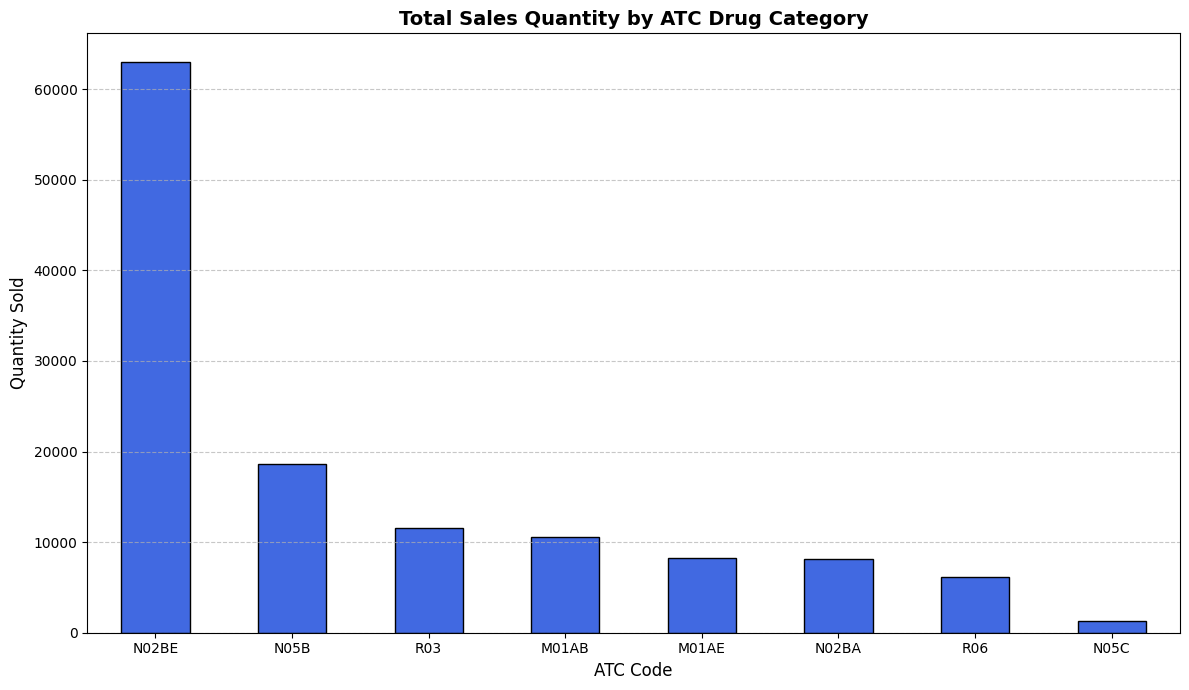

[INFO] 'r03_monthly_trend.jpg' has been saved successfully.


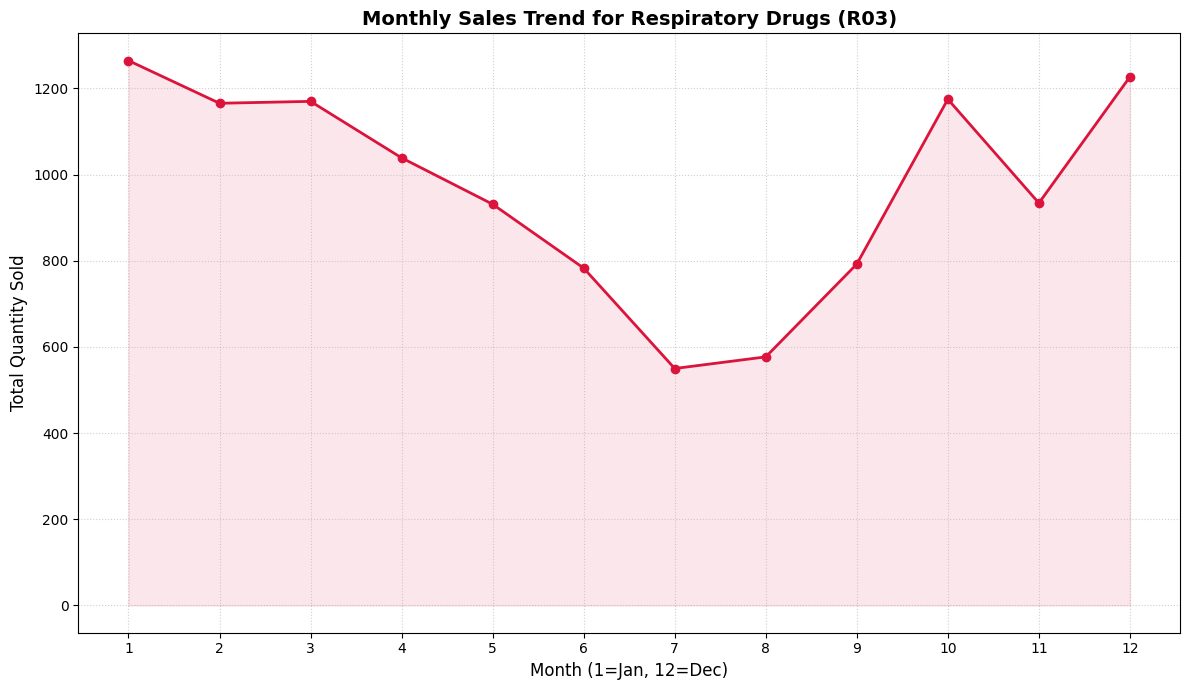


--- Analysis Complete ---


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = 'salesdaily.csv'

if not os.path.exists(file_path):
    print(f"Error: '{file_path}' not found. Please ensure the CSV is in the 'data' folder.")
    exit()

df = pd.read_csv(file_path)

df['datum'] = pd.to_datetime(df['datum'])

drug_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

print("--- PHARMACEUTICAL SALES ANALYSIS REPORT ---")

total_sales = df[drug_cols].sum().sort_values(ascending=False)
print("\n1. Total Sales Quantities per ATC Code:")
print(total_sales.to_string())

print(f"\n2. Highest Total Sales: {total_sales.idxmax()} ({total_sales.max():.2f} units)")

def get_top_3_monthly(year, month):
    subset = df[(df['Year'] == year) & (df['Month'] == month)]
    return subset[drug_cols].sum().sort_values(ascending=False).head(3)

print("\n3. Top 3 Drugs in specific periods:")
print(f"January 2015:\n{get_top_3_monthly(2015, 1)}")
print(f"\nJuly 2016:\n{get_top_3_monthly(2016, 7)}")
print(f"\nSeptember 2017:\n{get_top_3_monthly(2017, 9)}")

sales_2017 = df[df['Year'] == 2017][drug_cols].sum().sort_values(ascending=False)
print(f"\n4. Most sold drug in 2017: {sales_2017.idxmax()} ({sales_2017.max():.2f} units)")

avg_daily = df[drug_cols].mean().sort_values(ascending=False)
print(f"\n5. Highest Average Daily Sales: {avg_daily.idxmax()} ({avg_daily.max():.2f} units/day)")

r03_monthly = df.groupby('Month')['R03'].sum()
print("\n6. Monthly sales for Respiratory Drugs (R03):")
print(r03_monthly.to_string())

plt.figure(figsize=(12, 7))
total_sales.plot(kind='bar', color='royalblue', edgecolor='black')
plt.title('Total Sales Quantity by ATC Drug Category', fontsize=14, fontweight='bold')
plt.xlabel('ATC Code', fontsize=12)
plt.ylabel('Quantity Sold', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.savefig('total_sales_analysis.jpg', format='jpg', dpi=300)
print("\n[INFO] 'total_sales_analysis.jpg' has been saved successfully.")
plt.show()

plt.figure(figsize=(12, 7))
plt.plot(r03_monthly.index, r03_monthly.values, marker='o', linestyle='-', color='crimson', linewidth=2)
plt.title('Monthly Sales Trend for Respiratory Drugs (R03)', fontsize=14, fontweight='bold')
plt.xlabel('Month (1=Jan, 12=Dec)', fontsize=12)
plt.ylabel('Total Quantity Sold', fontsize=12)
plt.xticks(range(1, 13))
plt.grid(True, linestyle=':', alpha=0.6)
plt.fill_between(r03_monthly.index, r03_monthly.values, color='crimson', alpha=0.1)
plt.tight_layout()

plt.savefig('r03_monthly_trend.jpg', format='jpg', dpi=300)
print("[INFO] 'r03_monthly_trend.jpg' has been saved successfully.")
plt.show()

print("\n--- Analysis Complete ---")